# Task 1 - Smart Buildings HVAC Control Runs: Dataset Understanding and Probability

**Member 1 - Data Lead** (Sections 1-4). Sections 5-7 are reserved for Members 2-5.

> Member 5: refine the problem statement below before submission if the team's final angle changes.

## Problem and motivation
Heating, ventilation and air conditioning (HVAC) is a large share of a building's energy use and carbon emissions, yet it must also keep occupants comfortable and productive. The dataset records simulated HVAC control runs: a controller (the *policy*) operates a simulated building under a real-world-style weather file for two weeks, and the simulator reports, every 5 minutes, the building state (occupancy, outside and zone temperatures) and the reward signal split into comfort/productivity, energy cost and carbon terms. The setting matches a building-control competition or hackathon, where a team must design or evaluate a controller that lowers energy and carbon cost without hurting comfort.

## Objectives of Task 1
1. Understand the dataset: files, rows, columns, variable meanings and types, what one row represents, and its limitations.
2. Prepare it reproducibly: document every cleaning step with row and column counts before and after.
3. Define a shared set of **events** (Boolean columns) that Members 2-4 use to apply the Chapter 2 probability rules (sample space and events, counting, axioms, addition and multiplication rules, conditional probability, total probability, independence, Bayes' theorem).
4. Validate results with independent calculations, then summarise insights and limitations.

## Analysis steps
| Section | Content | Owner |
|---|---|---|
| 1 | Setup and data loading (raw file is never edited) | Member 1 |
| 2 | File structure, variables, data types, sample | Member 1 |
| 3 | Preprocessing and quality checks with a row-count log | Member 1 |
| 4 | Derived columns and shared event columns | Member 1 |
| 5 | Chapter 2 probability applications | Members 2-4 |
| 6 | Validation (direct counts vs rules, Monte Carlo, bootstrap, sensitivity) | Member 4 |
| 7 | Insights, limitations, relevance to the competition | Member 5 |

Scope note: all probabilities describe these 60 simulated runs, not real buildings. In this notebook a probability computed from the data is an **empirical relative frequency**: every one of the 241,920 time steps is treated as one equally likely outcome of the sample space.

## 1. Setup (Member 1)

Load the single source CSV without editing it. The notebook looks in the current folder, then in common Colab locations. If the file is not found and the notebook runs in Colab, it asks you to upload `combined_runsfinal.csv`. When running locally, keep the notebook beside the CSV or set `DATA_DIR` yourself.

The raw table `df_raw` is never modified; all cleaning is done on a copy called `df`, so the same code can be reused in later tasks and the final project.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

DATA_FILE = 'combined_runsfinal.csv'
candidate_dirs = [Path.cwd(), Path('/content'), Path('/content/drive/MyDrive/stats_project'),
                  Path('/content/drive/MyDrive'), Path('/mnt/user-data/uploads')]
DATA_DIR = next((p for p in candidate_dirs if (p / DATA_FILE).exists()), None)

if DATA_DIR is None:
    try:
        from google.colab import files
        print(f'Upload {DATA_FILE}')
        files.upload()
        DATA_DIR = Path.cwd()
    except ImportError:
        raise FileNotFoundError(f'Could not find {DATA_FILE}. Put it beside this notebook or set DATA_DIR.')

df_raw = pd.read_csv(DATA_DIR / DATA_FILE)      # untouched original
print('Data folder:', DATA_DIR)
print('Raw table  :', df_raw.shape[0], 'rows x', df_raw.shape[1], 'columns')
assert df_raw.shape == (241920, 37)

Data folder: /home/claude
Raw table  : 241920 rows x 37 columns


## 2. Understand the file and variables (Member 1)

**Files.** The project uses one file, `combined_runsfinal.csv`, which is the concatenation of 60 separate simulation runs.

**What one row means.** One row is one 5-minute time step of one run. A run is identified by `run_id`, which is exactly `building__weather__policy`.

**How the pieces relate.** The design is a full grid: 6 buildings x 5 cities (one weather file per building and city) x 2 control policies = 60 runs. Each run has 4,032 steps = 14 days at 5-minute spacing, so 60 x 4,032 = 241,920 rows. The weather file of a run fixes its calendar window in 2023 (different runs cover different two-week windows).

**Column groups.**
- *Identifiers:* `run_id`, `building`, `weather`, `policy`
- *Time:* `step`, `timestamp`
- *Step-level state and reward (change every row):* `reward`, `occupancy`, `outside_air_temp_K`, `zone_temp_mean_K`, `zone_temp_min_K`, `zone_temp_max_K`, `done`, and the reward components `rc_*`
- *Run-level summaries (repeated on every row of a run, constant within a run):* all `run_*` columns. These describe the building (zones, AHUs, floors, observation/action counts) or summarise the run (total/mean reward, average occupancy, average zone temperature, size, wall-clock seconds). Because they are repeated 4,032 times, row-level statistics on them over-weight each run. Use the 60-row `runs` table built in Section 4 for run-level questions.

In [2]:
overview = pd.Series({
    'files': 1,
    'rows (time steps)': len(df_raw),
    'columns': df_raw.shape[1],
    'runs (run_id)': df_raw.run_id.nunique(),
    'steps per run': int(df_raw.groupby('run_id').size().iloc[0]),
    'buildings': df_raw.building.nunique(),
    'weather files': df_raw.weather.nunique(),
    'cities': df_raw.weather.str.split('_').str[0].nunique(),
    'policies': df_raw.policy.nunique(),
    'time step': str(pd.to_datetime(df_raw.timestamp).diff().dropna().mode()[0]),
    'first timestamp': df_raw.timestamp.min(),
    'last timestamp': df_raw.timestamp.max(),
}, name='value')
display(overview.to_frame())

design = (df_raw.assign(city=df_raw.weather.str.split('_').str[0])
          .drop_duplicates('run_id')
          .pivot_table(index='building', columns='city', values='run_id', aggfunc='count'))
print('Runs per building x city (each cell = 2 policies):')
display(design)
print('Policies:', sorted(df_raw.policy.unique()))

,value
files,1
rows (time steps),241920
columns,37
runs (run_id),60
steps per run,4032
buildings,6
weather files,30
cities,5
policies,2
time step,0 days 00:05:00


Runs per building x city (each cell = 2 policies):


city,atlanta,denver,fairbanks,phoenix,singapore
building,,,,,
building_train_1,2,2,2,2,2
building_train_2,2,2,2,2,2
building_train_4,2,2,2,2,2
building_train_5,2,2,2,2,2
building_train_7,2,2,2,2,2
building_train_8,2,2,2,2,2


Policies: ['noisy_pid_water', 'pid_water']


In [3]:
# A small readable sample: the first occupied steps of the first run, with a few run-level columns
sample_cols = ['run_id', 'step', 'timestamp', 'reward', 'occupancy', 'outside_air_temp_K',
               'zone_temp_mean_K', 'zone_temp_min_K', 'zone_temp_max_K', 'rc_electricity_energy_cost',
               'rc_carbon_emitted', 'run_n_zones', 'run_n_floors']
df_raw[df_raw.occupancy > 0][sample_cols].head(5)

,run_id,step,timestamp,reward,occupancy,outside_air_temp_K,zone_temp_mean_K,zone_temp_min_K,zone_temp_max_K,rc_electricity_energy_cost,rc_carbon_emitted,run_n_zones,run_n_floors
287,building_train_1__atlanta_2__noisy_pid_water,287,2023-03-06T06:00:00,0.000000,4,286.450,293.704,292.492,294.972,0.000000,0.000000,39,3
288,building_train_1__atlanta_2__noisy_pid_water,288,2023-03-06T06:05:00,-0.036065,8,286.542,293.701,292.484,294.973,0.223110,1.659840,39,3
289,building_train_1__atlanta_2__noisy_pid_water,289,2023-03-06T06:10:00,-0.034681,10,286.633,294.826,293.621,296.296,0.195745,1.625500,39,3
290,building_train_1__atlanta_2__noisy_pid_water,290,2023-03-06T06:15:00,-0.011285,12,286.725,295.418,293.936,297.441,0.000000,0.628416,39,3
291,building_train_1__atlanta_2__noisy_pid_water,291,2023-03-06T06:20:00,0.000000,13,286.817,295.002,294.193,296.065,0.000000,0.000000,39,3


### Variable dictionary

Every one of the 37 CSV columns is listed below. `meaning` is a plain-English reading based on the column name and its values (temperatures are in Kelvin; subtract 273.15 for degrees Celsius). The `rc_` prefix is read as "reward component". The exact definition of each reward term comes from the simulator documentation, so treat the meanings as our working interpretation.

In [4]:
meaning = {
 'run_id': 'Unique run key = building__weather__policy',
 'building': 'Simulated building (6 different layouts)',
 'weather': 'Weather file: city_number (5 cities, 6 files each, one per building)',
 'policy': 'Control policy used (pid_water or noisy_pid_water)',
 'step': 'Time-step index inside a run (0 to 4031)',
 'timestamp': 'Date and time of the step (5-minute spacing, 2023)',
 'reward': 'Reward the controller received at this step (<= 0; closer to 0 is better)',
 'occupancy': 'Number of occupants in the building at this step',
 'outside_air_temp_K': 'Outdoor air temperature (K)',
 'zone_temp_mean_K': 'Mean temperature across zones (K)',
 'zone_temp_min_K': 'Coldest zone temperature (K)',
 'zone_temp_max_K': 'Warmest zone temperature (K)',
 'done': 'Episode-finished flag (always 0 in this file)',
 'rc_agent_reward': 'Agent reward as logged by the reward component (identical to reward)',
 'rc_productivity_reward': 'Productivity/comfort reward component (positive when occupied)',
 'rc_electricity_energy_cost': 'Electricity cost at this step',
 'rc_natural_gas_energy_cost': 'Natural-gas cost at this step',
 'rc_carbon_emitted': 'Carbon emitted at this step',
 'rc_normalized_productivity_regret': 'Productivity regret, normalised (<= 0)',
 'rc_normalized_energy_cost': 'Energy cost, normalised',
 'rc_normalized_carbon_emission': 'Carbon emission, normalised',
 'rc_total_occupancy': 'Total occupancy as logged by the reward component',
 'run_status': 'Run completion status (always ok)',
 'run_steps': 'Number of steps in the run (always 4032)',
 'run_total_reward': 'Run-level: sum of reward over the run',
 'run_mean_reward': 'Run-level: mean reward over the run',
 'run_score_abs_mean': 'Run-level: absolute value of the mean reward',
 'run_avg_occupancy': 'Run-level: mean occupancy',
 'run_avg_zone_temp_K': 'Run-level: mean zone temperature (K)',
 'run_n_obs': 'Building: size of the observation vector',
 'run_n_cont_actions': 'Building: number of continuous actions',
 'run_n_disc_actions': 'Building: number of discrete actions',
 'run_n_ahus': 'Building: number of air-handling units (AHUs)',
 'run_n_zones': 'Building: number of thermal zones',
 'run_n_floors': 'Building: number of floors',
 'run_size_mb': 'Run-level: size of the stored run (MB)',
 'run_seconds': 'Run-level: simulation wall-clock time (s)',
}
step_level_groups = {'identifier': ['run_id', 'building', 'weather', 'policy'],
                     'time': ['step', 'timestamp']}

def level_of(c):
    return 'run-level (constant within run)' if df_raw.groupby('run_id')[c].nunique().max() == 1 else 'step-level'

def dtype_of(c):
    s = df_raw[c]
    if c in ('run_id',):
        return 'identifier (text)'
    if c == 'timestamp':
        return 'date/time (stored as text)'
    if c == 'step':
        return 'numeric-discrete (time index)'
    if s.nunique() == 1:
        return 'constant'
    if s.dtype == object or str(s.dtype).startswith('str'):
        return 'categorical (text)'
    return 'numeric-discrete' if pd.api.types.is_integer_dtype(s) else 'numeric-continuous'

variable_dictionary = pd.DataFrame({
    'column': df_raw.columns,
    'pandas dtype': [str(df_raw[c].dtype) for c in df_raw.columns],
    'type': [dtype_of(c) for c in df_raw.columns],
    'level': [level_of(c) for c in df_raw.columns],
    'distinct values': [df_raw[c].nunique() for c in df_raw.columns],
    'meaning': [meaning[c] for c in df_raw.columns],
})
assert len(variable_dictionary) == 37
display(variable_dictionary)

,column,pandas dtype,type,level,distinct values,meaning
0,run_id,str,identifier (text),run-level (constant within run),60,Unique run key = building__weather__policy
1,building,str,categorical (text),run-level (constant within run),6,Simulated building (6 different layouts)
2,weather,str,categorical (text),run-level (constant within run),30,"Weather file: city_number (5 cities, 6 files e..."
3,policy,str,categorical (text),run-level (constant within run),2,Control policy used (pid_water or noisy_pid_wa...
4,step,int64,numeric-discrete (time index),step-level,4032,Time-step index inside a run (0 to 4031)
5,timestamp,str,date/time (stored as text),step-level,80640,"Date and time of the step (5-minute spacing, 2..."
6,reward,float64,numeric-continuous,step-level,175525,Reward the controller received at this step (<...
7,occupancy,int64,numeric-discrete,step-level,161,Number of occupants in the building at this step
8,outside_air_temp_K,float64,numeric-continuous,step-level,6721,Outdoor air temperature (K)
9,zone_temp_mean_K,float64,numeric-continuous,step-level,11965,Mean temperature across zones (K)


## 3. Preprocessing and quality checks (Member 1)

**Plan.** The file is machine generated, so we expect it to be clean. We verify that instead of assuming it:
- missing values and duplicate rows,
- one row per (`run_id`, `step`) with steps 0..4031 and exact 5-minute spacing,
- every run is one building x one weather file x one policy,
- minimum <= mean <= maximum for zone temperatures,
- run-level summary columns agree with values recomputed from the step rows.

**Decisions.**
1. **No rows are removed.** Nothing is missing, duplicated or invalid, and removing rows would change the denominators of every probability.
2. **Parse `timestamp`** into a real datetime so hour, weekday and date events can be built.
3. **Drop constant and redundant columns in the analysis copy only:** `done`, `run_status` and `run_steps` are constant (they cannot define a non-trivial event), and `rc_agent_reward` is an exact copy of `reward`. They stay available in `df_raw`.
4. **Keep valid extremes** (for example 160 occupants, very low rewards, Fairbanks winter temperatures near 231 K). They are real simulator outputs and removing them would bias the probabilities.

In [5]:
preprocess_log = []
def log_step(name, frame):
    preprocess_log.append({'step': name, 'rows': len(frame), 'columns': frame.shape[1]})
    print(f'{name}: {len(frame):,} rows x {frame.shape[1]} columns')

log_step('Raw file loaded (df_raw)', df_raw)

df = df_raw.copy()
df['timestamp'] = pd.to_datetime(df['timestamp'])
log_step('Parsed timestamp to datetime', df)

# ---------- quality checks (assert = fail loudly if the data ever changes) ----------
missing_total = int(df_raw.isna().sum().sum())
dup_rows = int(df_raw.duplicated().sum())
dup_keys = int(df_raw.duplicated(['run_id', 'step']).sum())
g = df.groupby('run_id')
steps_per_run = g.size()
step_contiguous = g.step.apply(lambda s: (s.values == np.arange(len(s))).all()).all()
regular_5min = g.timestamp.apply(lambda s: (s.diff().dropna() == pd.Timedelta(minutes=5)).all()).all()
run_id_ok = (df.run_id == df.building + '__' + df.weather + '__' + df.policy).all()
one_combo_per_run = (g[['building', 'weather', 'policy']].nunique() == 1).all().all()
balanced_design = (df.drop_duplicates('run_id').assign(city=lambda d: d.weather.str.split('_').str[0])
                   .groupby(['building', 'city', 'policy']).size() == 1).all()
temp_order_ok = ((df.zone_temp_min_K <= df.zone_temp_mean_K) & (df.zone_temp_mean_K <= df.zone_temp_max_K)).all()
reward_copy = np.allclose(df.reward, df.rc_agent_reward)
reward_nonpositive = (df.reward <= 0).all()
occ_nonneg_int = (df.occupancy >= 0).all() and pd.api.types.is_integer_dtype(df.occupancy)

# run-level summaries recomputed from the step rows (tolerance for rounding)
chk = g.agg(m=('reward', 'mean'), tot=('reward', 'sum'), occ=('occupancy', 'mean'), zt=('zone_temp_mean_K', 'mean'),
            rm=('run_mean_reward', 'first'), rt=('run_total_reward', 'first'),
            ro=('run_avg_occupancy', 'first'), rz=('run_avg_zone_temp_K', 'first'))
summaries_ok = (np.allclose(chk.m, chk.rm, atol=1e-6) and np.allclose(chk.tot, chk.rt, atol=1e-3)
                and np.allclose(chk.occ, chk.ro, atol=1e-6) and np.allclose(chk.zt, chk.rz, atol=1e-3))

assert missing_total == 0 and dup_rows == 0 and dup_keys == 0
assert (steps_per_run == 4032).all() and step_contiguous and regular_5min
assert run_id_ok and one_combo_per_run and balanced_design
assert temp_order_ok and reward_copy and summaries_ok

quality_checks = pd.Series({
    'missing cells (whole file)': missing_total,
    'fully duplicated rows': dup_rows,
    'duplicated (run_id, step) keys': dup_keys,
    'every run has 4032 steps': bool((steps_per_run == 4032).all()),
    'steps are 0..4031 with no gaps': bool(step_contiguous),
    'timestamps spaced exactly 5 min': bool(regular_5min),
    'run_id == building__weather__policy': bool(run_id_ok),
    'one building/weather/policy per run': bool(one_combo_per_run),
    'balanced 6 x 5 x 2 design (1 run per cell)': bool(balanced_design),
    'zone temp: min <= mean <= max': bool(temp_order_ok),
    'reward <= 0 everywhere': bool(reward_nonpositive),
    'occupancy is a non-negative integer': bool(occ_nonneg_int),
    'rc_agent_reward identical to reward': bool(reward_copy),
    'run_* summaries match recomputation': bool(summaries_ok),
}, name='result')
display(quality_checks.to_frame())

# ---------- drop constant / redundant columns in the analysis copy ----------
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
redundant_cols = ['rc_agent_reward']
df = df.drop(columns=const_cols + redundant_cols)
log_step(f'Dropped {len(const_cols)} constant columns {const_cols} + redundant {redundant_cols}', df)

Raw file loaded (df_raw): 241,920 rows x 37 columns
Parsed timestamp to datetime: 241,920 rows x 37 columns


,result
missing cells (whole file),0
fully duplicated rows,0
"duplicated (run_id, step) keys",0
every run has 4032 steps,True
steps are 0..4031 with no gaps,True
timestamps spaced exactly 5 min,True
run_id == building__weather__policy,True
one building/weather/policy per run,True
balanced 6 x 5 x 2 design (1 run per cell),True
zone temp: min <= mean <= max,True


Dropped 3 constant columns ['done', 'run_status', 'run_steps'] + redundant ['rc_agent_reward']: 241,920 rows x 33 columns


In [6]:
# How do preprocessing choices affect the probabilities? Two things worth knowing up front.

# (1) Step 0 of every run has reward exactly 0 (start-up). 60 rows = 0.025% of the data.
first = df.step == 0
print('Rows with step 0:', int(first.sum()), '| reward == 0 on all of them:', bool((df.loc[first, 'reward'] == 0).all()))
p_all = (df.reward < 0).mean()
p_no0 = (df.loc[~first, 'reward'] < 0).mean()
print(f'P(reward < 0): all rows = {p_all:.5f}, without step 0 = {p_no0:.5f}  (difference {abs(p_all-p_no0):.5f})')
log_step('What-if: remove step 0 (NOT applied, sensitivity only)', df[~first])

# (2) `occupancy` and `rc_total_occupancy` are two logged occupancy counts that do not always agree.
diff_rows = (df_raw.occupancy != df_raw.rc_total_occupancy).mean()
occ_a, occ_b = df_raw.occupancy > 0, df_raw.rc_total_occupancy > 0
print(f'\nRows where the two counts differ: {diff_rows:.3%}')
print(f'P(occupied) using occupancy > 0           : {occ_a.mean():.5f}')
print(f'P(occupied) using rc_total_occupancy > 0  : {occ_b.mean():.5f}')
print(f'Rows where the occupied/empty flag differs: {(occ_a != occ_b).mean():.3%}')

Rows with step 0: 60 | reward == 0 on all of them: True
P(reward < 0): all rows = 0.81857, without step 0 = 0.81877  (difference 0.00020)
What-if: remove step 0 (NOT applied, sensitivity only): 241,860 rows x 33 columns

Rows where the two counts differ: 34.301%
P(occupied) using occupancy > 0           : 0.37348
P(occupied) using rc_total_occupancy > 0  : 0.37362
Rows where the occupied/empty flag differs: 0.085%


In [7]:
pd.DataFrame(preprocess_log)

,step,rows,columns
0,Raw file loaded (df_raw),241920,37
1,Parsed timestamp to datetime,241920,37
2,"Dropped 3 constant columns ['done', 'run_statu...",241920,33
3,"What-if: remove step 0 (NOT applied, sensitivi...",241860,33


## 4. Derived columns and shared event columns (Member 1)

**Derived columns.** `city` (from `weather`), `hour`, `dayofweek`, `is_weekend`, and temperatures in degrees Celsius for readability.

**Run table.** `runs` has one row per run (60 rows) with the building and run-level summaries. Use it for questions about buildings or policies so that every run counts once.

**Shared event columns.** These Boolean columns are published for all members and must not be renamed. Thresholds are stated explicitly and use strict `>` or `<`, so ties are not counted in the event.

| Column | Event (meaning) | Rule |
|---|---|---|
| `A_occupied` | People are in the building | `occupancy > 0` |
| `B_low_reward` | Poor step reward (worst quarter) | `reward <` 25th percentile of all rewards |
| `C_hot_outside` | Hot weather | `outside_air_temp_K > 298.15` (25 deg C) |
| `D_high_energy` | High energy cost step | `rc_normalized_energy_cost >` median |
| `E_noisy` | Noisy controller | `policy == 'noisy_pid_water'` |
| `G_hot_zone` | Some zone is warm | `zone_temp_max_K > 299.15` (26 deg C) |
| `H_work_hours` | Typical working hours | hour between 6 and 18 inclusive (all occupied steps fall here) |
| `L_large` | Large building | `run_n_zones >` median zone count over the 6 buildings (46.5) |
| `F2`, `F3`, `F4` | Building has 2, 3 or 4 floors | `run_n_floors == k` |

The 26 deg C and 25 deg C cut-offs are convenient round thresholds, not official comfort limits. The median and percentile thresholds are conventions chosen to make events neither rare nor almost certain.

In [8]:
# ---------- derived columns ----------
df['city'] = df.weather.str.split('_').str[0]
df['hour'] = df.timestamp.dt.hour
df['dayofweek'] = df.timestamp.dt.dayofweek          # Monday = 0
df['is_weekend'] = df.dayofweek >= 5
df['outside_air_temp_C'] = df.outside_air_temp_K - 273.15
df['zone_temp_mean_C'] = df.zone_temp_mean_K - 273.15
log_step('Added derived columns (city, hour, dayofweek, is_weekend, Celsius temps)', df)

# ---------- run table (one row per run) ----------
run_cols = ['run_id', 'building', 'weather', 'city', 'policy', 'run_n_zones', 'run_n_ahus', 'run_n_floors',
            'run_n_obs', 'run_n_cont_actions', 'run_n_disc_actions', 'run_total_reward', 'run_mean_reward',
            'run_avg_occupancy', 'run_avg_zone_temp_K', 'run_size_mb', 'run_seconds']
runs = df.drop_duplicates('run_id')[run_cols].reset_index(drop=True)
assert len(runs) == 60
buildings = runs.drop_duplicates('building')[['building', 'run_n_zones', 'run_n_ahus', 'run_n_floors']].set_index('building')
display(buildings)

# ---------- shared event columns ----------
reward_q1 = df.reward.quantile(0.25)
energy_median = df.rc_normalized_energy_cost.median()
zone_median = buildings.run_n_zones.median()
print(f'Thresholds -> reward Q1 = {reward_q1:.5f}, energy median = {energy_median:.5f}, zone median = {zone_median}')

df['A_occupied'] = df.occupancy > 0
df['B_low_reward'] = df.reward < reward_q1
df['C_hot_outside'] = df.outside_air_temp_K > 298.15
df['D_high_energy'] = df.rc_normalized_energy_cost > energy_median
df['E_noisy'] = df.policy == 'noisy_pid_water'
df['G_hot_zone'] = df.zone_temp_max_K > 299.15
df['H_work_hours'] = df.hour.between(6, 18)
df['L_large'] = df.run_n_zones > zone_median
df['F2'] = df.run_n_floors == 2
df['F3'] = df.run_n_floors == 3
df['F4'] = df.run_n_floors == 4

EVENT_COLS = ['A_occupied', 'B_low_reward', 'C_hot_outside', 'D_high_energy', 'E_noisy',
              'G_hot_zone', 'H_work_hours', 'L_large', 'F2', 'F3', 'F4']
assert all(df[c].dtype == bool for c in EVENT_COLS)
assert (df.F2 | df.F3 | df.F4).all() and ((df.F2.astype(int) + df.F3 + df.F4) == 1).all()   # floors partition the space
assert (df.A_occupied <= df.H_work_hours).all()      # occupied implies working hours

n = len(df)
event_table = pd.DataFrame({
    'count': df[EVENT_COLS].sum(),
    'P(event)': df[EVENT_COLS].mean().round(4),
})
event_table['share of rows'] = (event_table['count'] / n).map('{:.2%}'.format)
display(event_table)
log_step('Added shared event columns (no rows removed)', df)
print('Shared event columns:', EVENT_COLS)
print('\nComplete preprocessing log:')
display(pd.DataFrame(preprocess_log))

Added derived columns (city, hour, dayofweek, is_weekend, Celsius temps): 241,920 rows x 39 columns


,run_n_zones,run_n_ahus,run_n_floors
building,,,
building_train_1,39,4,3
building_train_2,85,9,2
building_train_4,54,6,3
building_train_5,79,8,4
building_train_7,36,4,2
building_train_8,30,3,2


Thresholds -> reward Q1 = -0.07973, energy median = 0.00588, zone median = 46.5


,count,P(event),share of rows
A_occupied,90352,0.3735,37.35%
B_low_reward,60480,0.2500,25.00%
C_hot_outside,93406,0.3861,38.61%
D_high_energy,120960,0.5000,50.00%
E_noisy,120960,0.5000,50.00%
G_hot_zone,78016,0.3225,32.25%
H_work_hours,131040,0.5417,54.17%
L_large,120960,0.5000,50.00%
F2,120960,0.5000,50.00%
F3,80640,0.3333,33.33%


Added shared event columns (no rows removed): 241,920 rows x 50 columns
Shared event columns: ['A_occupied', 'B_low_reward', 'C_hot_outside', 'D_high_energy', 'E_noisy', 'G_hot_zone', 'H_work_hours', 'L_large', 'F2', 'F3', 'F4']

Complete preprocessing log:


,step,rows,columns
0,Raw file loaded (df_raw),241920,37
1,Parsed timestamp to datetime,241920,37
2,"Dropped 3 constant columns ['done', 'run_statu...",241920,33
3,"What-if: remove step 0 (NOT applied, sensitivi...",241860,33
4,"Added derived columns (city, hour, dayofweek, ...",241920,39
5,Added shared event columns (no rows removed),241920,50


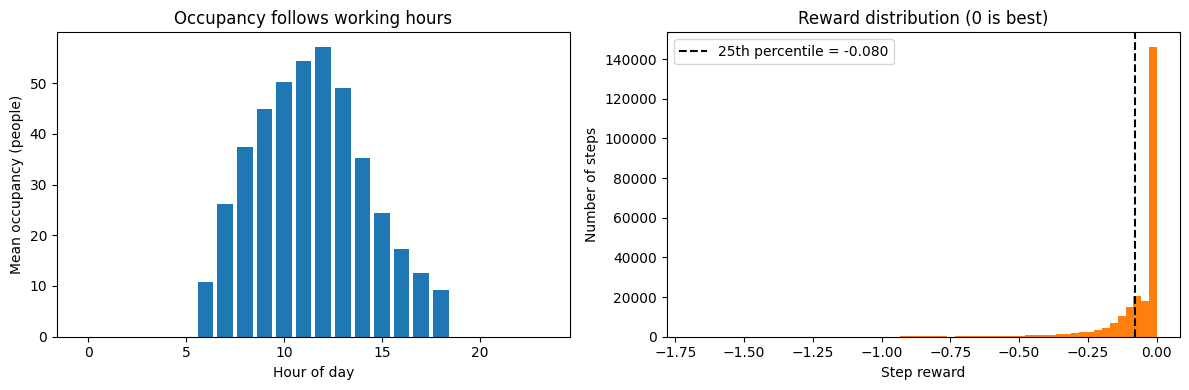

,mean_outside_C,P_hot_outside,P_low_reward
city,,,
atlanta,17.521,0.242,0.187
denver,13.328,0.136,0.206
fairbanks,-0.955,0.012,0.322
phoenix,26.572,0.590,0.280
singapore,28.086,0.950,0.255


In [9]:
# Two quick pictures of the data (more charts are added by Members 2-5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

hourly = df.groupby('hour').agg(occ=('occupancy', 'mean'), p_occ=('A_occupied', 'mean'))
axes[0].bar(hourly.index, hourly.occ, color='tab:blue')
axes[0].set_xlabel('Hour of day'); axes[0].set_ylabel('Mean occupancy (people)')
axes[0].set_title('Occupancy follows working hours')

axes[1].hist(df.reward, bins=60, color='tab:orange')
axes[1].axvline(reward_q1, color='k', ls='--', label=f'25th percentile = {reward_q1:.3f}')
axes[1].set_xlabel('Step reward'); axes[1].set_ylabel('Number of steps')
axes[1].set_title('Reward distribution (0 is best)'); axes[1].legend()
plt.tight_layout(); plt.show()

city_tab = df.groupby('city').agg(mean_outside_C=('outside_air_temp_C', 'mean'),
                                  P_hot_outside=('C_hot_outside', 'mean'),
                                  P_low_reward=('B_low_reward', 'mean')).round(3)
display(city_tab)

### Preprocessing notes and limitations (Member 1)

**What changed.** No rows were removed: all 241,920 steps (60 runs) are kept. The analysis copy `df` has fewer raw columns (4 constant or redundant columns dropped) and extra derived and event columns. The raw table `df_raw` is untouched. Dropping the constant columns does not change any event probability.

**Choices that can affect probabilities.**
- Step 0 of each run has reward exactly 0 by construction. Keeping it shifts `P(reward < 0)` by only about 0.0002 (see the sensitivity cell), so it is kept.
- Two occupancy columns exist and disagree on about a third of rows by count, but they give almost the same `P(occupied)`. We use `occupancy`; Member 4 can rerun key results with `rc_total_occupancy`.
- Event thresholds (percentile, median, 25 deg C, 26 deg C) are conventions. Changing them changes the numbers, so any threshold must be stated next to its result.

**Limitations.**
- The data are simulator outputs for 6 buildings, 5 cities and 2 controllers. They are not a random sample of real buildings, so conclusions are conditional on this design.
- Consecutive 5-minute steps within a run are strongly dependent (temperature, occupancy and reward drift slowly), so the 241,920 rows are far fewer than 241,920 independent observations. Frequencies are fine as descriptions, but independence-based reasoning and confidence intervals should resample whole runs or days, not single rows.
- `run_*` columns repeat per row; use the `runs` table for building- or run-level questions.
- Each (building, city) pair has exactly one weather file, so weather and building effects are partly entangled with the calendar window of that file.
- Only two policies are present, both PID-style water controllers; there is no learned (reinforcement-learning) policy to compare against.
- Occupancy is zero on every Saturday and Sunday step and outside roughly 06:00-18:59 (see the hourly chart). Any conditional probability given `A_occupied` is therefore a weekday working-hours statement, and `H_work_hours` (which includes weekends) is not the same event as `A_occupied`.

## 5. Probability applications (Members 2-4)

Add each application with the five-part template required by the task:
1. **Question** - a meaningful question about the Smart Buildings data
2. **Events and assumptions** - use the shared columns from Section 4 (`A_occupied`, `B_low_reward`, ..., `F2`, `F3`, `F4`) and state what is assumed
3. **Rule and why it fits** - sample space and events, counting, axioms, addition rule, multiplication rule, conditional probability, total probability, independence, Bayes' theorem
4. **Calculation and result** - show the formula and the number
5. **Interpretation** - what it means for building control

Suggested starting points (each uses the shared events):
- Addition rule: `P(A_occupied or C_hot_outside)`
- Conditional probability: `P(B_low_reward | A_occupied)` versus `P(B_low_reward | not A_occupied)`
- Total probability: split `B_low_reward` over `F2`, `F3`, `F4` or over the five cities
- Independence: is `E_noisy` independent of `B_low_reward`? Is `L_large` independent of `D_high_energy`?
- Bayes: `P(E_noisy | B_low_reward)`
- Counting: number of distinct (building, city, policy) runs, ordered or unordered pairs of buildings, and so on

Keep this section after the shared event cell. If a rule cannot be applied directly (for example independence between consecutive steps), explain why and use a suitable alternative.

## 6. Validation (Member 4)

Compare every major rule-based result with a direct calculation from the rows (for example `P(A and B)` from the multiplication rule versus the observed share of rows where both are true). Add independent approaches where possible: grouping with `crosstab`, Monte Carlo simulation, and a bootstrap interval that **resamples whole runs or days** (not single steps, because steps within a run are dependent). Include the preprocessing sensitivity analysis (step 0, `rc_total_occupancy`, alternative thresholds). Explain exact agreement versus differences caused by sampling or modelling assumptions.

## 7. Insights and limitations (Member 5)

Summarise the main patterns with numbers, discuss the assumptions and limitations (see Section 4 notes), and explain how the findings help in the Smart Buildings competition or hackathon (for example, identifying when and where controllers lose reward, and which building or weather conditions make low-reward steps more likely).